# Learning Fair Representations on Adult, German and COMPAS

INFOMDW Assignment 4, Task 2. Evaluation of

> R. Zemel, Y. Wu, K. Swersky, T. Pitassi and C. Dwork. *Learning Fair Representations.* ICML 2013, PMLR 28(3):325–333.
> [paper](https://proceedings.mlr.press/v28/zemel13.html)

with the implementation in [AIF360](https://github.com/Trusted-AI/AIF360) 0.6.1 (`aif360.algorithms.preprocessing.LFR`).

**Pipeline** (pre-processing): measure the original labels → stratified train/test split → learn the fair
representation on the training data only → train the final classifier on the transformed training data →
transform the test data and predict → measure DP_diff, DIR, consistency, accuracy and balanced accuracy on the test set.

**Run** (from the repository root): `bash reproduce.sh`, or open this notebook with the `.venv` kernel after `uv sync --locked`.
Environment variables: `REPRODUCE_QUICK=1` runs a 1-seed, 3-setting smoke test (about a minute);
`REPRODUCE_REUSE=1` keeps per-task result files that already exist in `results/raw/runs/`;
`REPRODUCE_WORKERS=n` sets the number of parallel processes. The settings themselves are fixed in `run_experiments.py`.

In [1]:
import logging, os, warnings
logging.getLogger().setLevel(logging.ERROR)        # AIF360 logs a warning per optional algorithm it cannot import
warnings.filterwarnings("ignore", category=SyntaxWarning)

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from aif360.algorithms.preprocessing import LFR

import datasets, lfr as L, make_tables, run_experiments as E

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
QUICK = os.environ.get("REPRODUCE_QUICK") == "1"
REUSE = os.environ.get("REPRODUCE_REUSE") == "1"
pd.Series({"seeds": E.QUICK["seeds"] if QUICK else E.SEEDS, "test share": E.TEST_SIZE,
           "validation share of train": E.VALIDATION_SIZE, "prototypes k": E.K_PROTOTYPES, "Ax": E.AX,
           "Ay grid": E.QUICK["ay"] if QUICK else E.AY_GRID, "Az grid": E.QUICK["az"] if QUICK else E.AZ_GRID,
           "threshold": E.THRESHOLD, "L-BFGS-B maxiter = maxfun": E.MAXITER,
           "logistic regression": E.LR_PARAMS, "consistency k": E.K_NEIGHBOURS,
           "quick run": QUICK, "reuse cached runs": REUSE}, name="setting").to_frame()

,setting
seeds,"[0, 1, 2, 3, 4]"
test share,0.3
validation share of train,0.2
prototypes k,10
Ax,0.01
Ay grid,"[0.1, 0.5, 1, 5, 10]"
Az grid,"[0, 0.1, 0.5, 1, 5, 10]"
threshold,0.5
L-BFGS-B maxiter = maxfun,5000
logistic regression,{'max_iter': 1000}


## 1. Data

Raw files are downloaded on first use and checked against SHA256 hashes recorded in `datasets.py`
(UCI archives for Adult and German; the ProPublica repository pinned to a commit for COMPAS).
The datasets are built with AIF360's `StandardDataset` using the options of AIF360's own dataset classes,
with one protected attribute each; deviations are commented in `datasets.py`.

In [2]:
data = {name: datasets.load(name) for name in datasets.DATASETS}
pd.DataFrame([{"dataset": n, "rows": ds.features.shape[0], "features after one-hot": ds.features.shape[1],
               "protected attribute": pa, **{k: v for k, v in datasets.DESCRIPTION[n].items() if k != "protected"},
               "privileged share": ds.protected_attributes.mean(), "favourable share": ds.labels.mean()}
              for n, (ds, pa) in data.items()]).set_index("dataset")

,rows,features after one-hot,protected attribute,privileged,unprivileged,favourable,privileged share,favourable share
dataset,,,,,,,,
adult,45222,102,sex,male,female,income > 50K,0.675,0.248
german,1000,61,age,age > 25,age <= 25,good credit,0.810,0.700
compas,6172,13,race,Caucasian,not Caucasian,no recidivism in two years,0.341,0.545


## 2. Fairness of the original labels (before any split, mitigation or classifier)

Measured on the complete datasets. DP_diff = P(y=1 | unprivileged) − P(y=1 | privileged), DIR = the ratio of the
same two rates, consistency = Zemel et al.'s yNN with k = 5 neighbours (AIF360 `consistency()`), computed on
z-scored features. AIF360 applied to the raw features is shown for comparison: there the distances are dominated
by wide-range columns (e.g. capital-gain in Adult).

In [3]:
before = []
for name, (ds, pa) in data.items():
    z = StandardScaler().fit_transform(ds.features)
    before.append({"dataset": name, **E.fairness(ds, pa, ds.labels, z)})
before = pd.DataFrame(before).set_index("dataset")
before[["pos_rate_unpriv", "pos_rate_priv", "DP_diff", "DIR", "consistency", "consistency_raw"]]

,pos_rate_unpriv,pos_rate_priv,DP_diff,DIR,consistency,consistency_raw
dataset,,,,,,
adult,0.114,0.312,-0.199,0.363,0.828,0.849
german,0.579,0.728,-0.149,0.795,0.736,0.682
compas,0.512,0.609,-0.097,0.840,0.658,0.663


## 3. The pipeline step by step (German, seed 0, one LFR setting)

This section shows every step on one split; section 4 repeats exactly these steps (in `run_experiments.run_seed`)
for every dataset, seed and grid setting.

**3a. Stratified split.** Strata are label × protected group. 70 % train / 30 % test; the train part is split
again (80 % fit / 20 % validation) because Zemel et al. choose the hyper-parameters on a validation set.

In [4]:
ds, pa = data["german"]
idx = E.split(ds, seed=0)
parts = {p: ds.subset(i) for p, i in idx.items()}
pd.DataFrame({p: {"rows": len(d.labels), "favourable share": d.labels.mean(),
                  "privileged share": d.protected_attributes.mean()} for p, d in parts.items()}).T

,rows,favourable share,privileged share
fit,560.0,0.7,0.809
val,140.0,0.7,0.814
test,300.0,0.7,0.810


**3b. Scaling and baseline.** Features are z-scored with statistics of the fit part only. The baseline is a
logistic regression on the original features, without mitigation.

In [5]:
scaler = StandardScaler().fit(parts["fit"].features)
scaled = {p: d.copy(deepcopy=True) for p, d in parts.items()}
for p in scaled:
    scaled[p].features = scaler.transform(parts[p].features)

baseline = LogisticRegression(**E.LR_PARAMS).fit(scaled["fit"].features, parts["fit"].labels.ravel())
y_base = baseline.predict(scaled["test"].features)

**3c. Learn the fair representation on the training data.** `ExactGradientLFR` is AIF360's `LFR` with one change:
`fit` gives L-BFGS-B the analytic gradient of AIF360's own objective instead of finite differences
(`tests/test_reproduction.py` checks that the objective is identical and the gradient correct). For comparison the
unchanged AIF360 `fit` is run with the same setting and seed; `L.fit_aif360` only records SciPy's report.

In [6]:
groups = {"unprivileged_groups": [{pa: 0.0}], "privileged_groups": [{pa: 1.0}]}
setting = {"k": E.K_PROTOTYPES, "Ax": E.AX, "Ay": 1.0, "Az": 1.0}
exact = L.ExactGradientLFR(**groups, **setting, seed=0).fit(scaled["fit"])
released = L.fit_aif360(LFR(**groups, **setting, seed=0), scaled["fit"])
pd.DataFrame({"exact gradient": exact.optimizer_info, "AIF360 as released": released.optimizer_info}).T

,objective,iterations,evaluations,converged,stop_reason
exact gradient,0.388,465,613,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
AIF360 as released,0.586,8,5589,False,"STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT"


**3d. Transform and predict.** Two complete pipelines on the held-out test data:

* *LFR classifier* — the model's own prediction ŷ = Σₖ Mₙₖ wₖ > 0.5 (AIF360's transformed labels; what the paper evaluates);
* *LR on LFR repr.* — a logistic regression trained on the transformed training data (AIF360's transformed
  features x̂ = Σₖ Mₙₖ vₖ) with the original training labels, applied to the transformed test data.

In [7]:
def evaluate(y_pred):
    test = parts["test"]
    return {**E.fairness(test, pa, y_pred, scaled["test"].features), **E.performance(test.labels, y_pred)}

rows = {"test labels (no model)": evaluate(parts["test"].labels), "LR baseline": evaluate(y_base)}
for label, model in (("exact gradient", exact), ("AIF360 as released", released)):
    y_lfr = (L.predict_proba(model, scaled["test"].features) > E.THRESHOLD).astype(float)
    assert np.array_equal(y_lfr, model.transform(scaled["test"]).labels.ravel())   # same as AIF360's transform
    downstream = LogisticRegression(**E.LR_PARAMS).fit(model.transform(scaled["fit"]).features,
                                                       parts["fit"].labels.ravel())
    rows[f"LFR classifier, {label}"] = evaluate(y_lfr)
    rows[f"LR on LFR repr., {label}"] = evaluate(downstream.predict(model.transform(scaled["test"]).features))
pd.DataFrame(rows).T[["DP_diff", "DIR", "consistency", "accuracy", "balanced_accuracy", "pos_rate"]]

,DP_diff,DIR,consistency,accuracy,balanced_accuracy,pos_rate
test labels (no model),-0.149,0.795,0.735,1.000,1.000,0.700
LR baseline,-0.169,0.798,0.820,0.743,0.645,0.803
"LFR classifier, exact gradient",0.010,1.012,0.824,0.737,0.631,0.817
"LR on LFR repr., exact gradient",0.050,1.066,0.795,0.740,0.659,0.767
"LFR classifier, AIF360 as released",0.050,1.056,0.939,0.707,0.552,0.907
"LR on LFR repr., AIF360 as released",-0.087,0.892,0.823,0.730,0.636,0.790


## 4. Full experiment

For each dataset and seed: the steps above for the 30 settings of the paper's grid (Ax = 0.01;
Ay ∈ {0.1, 0.5, 1, 5, 10}; Az ∈ {0, 0.1, 0.5, 1, 5, 10}), the selection of a setting on the validation set with the
paper's two criteria, and AIF360's unchanged `fit` with the selected setting and with AIF360's default setting.
Tasks run in parallel processes; every task writes `results/raw/runs/<dataset>_seed<seed>.csv`.

In [8]:
runs = E.run_all(quick=QUICK, reuse=REUSE)
print(f"{len(runs)} result rows")

1980 result rows


## 5. Results

`make_tables.py` writes `results/results.md`, `results/summary.csv` and `results/tradeoff.png` from `results/raw/`.
Test-set values below are mean ± standard deviation over the seeds.

In [9]:
make_tables.main()
summary = pd.read_csv("results/summary.csv")
sel = make_tables.selected_rows(runs)
show = ["Test labels (no model)", "LR baseline (no mitigation)"] + make_tables.ORDER[2:]
for name in datasets.DATASETS:
    s = summary[summary["dataset"] == name].set_index("pipeline").loc[[p for p in show if p in set(summary["pipeline"])]]
    table = pd.DataFrame({m: [make_tables.fmt(a, b) for a, b in zip(s[m + "_mean"], s[m + "_sd"])]
                          for m in make_tables.MEASURES}, index=s.index)
    display(Markdown(f"### {make_tables.NAMES[name]}"), table)

wrote results/results.md, results/summary.csv and results/tradeoff.png


### Adult (sex)

,DP_diff,DIR,consistency,accuracy,balanced_accuracy,pos_rate
pipeline,,,,,,
Test labels (no model),-0.199 ± 0.000,0.364 ± 0.000,0.822 ± 0.002,1.000 ± 0.000,1.000 ± 0.000,0.248 ± 0.000
LR baseline (no mitigation),-0.189 ± 0.006,0.284 ± 0.013,0.942 ± 0.002,0.847 ± 0.002,0.764 ± 0.004,0.202 ± 0.003
"LFR classifier, exact gradient, max Delta",-0.007 ± 0.008,0.957 ± 0.045,0.968 ± 0.010,0.818 ± 0.006,0.689 ± 0.018,0.148 ± 0.016
"LR on LFR repr., exact gradient, max Delta",-0.018 ± 0.010,0.904 ± 0.051,0.958 ± 0.006,0.823 ± 0.004,0.720 ± 0.005,0.185 ± 0.003
"LFR classifier, exact gradient, min yDiscrim",0.000 ± 0.000,–,1.000 ± 0.000,0.752 ± 0.000,0.500 ± 0.000,0.000 ± 0.000
"LR on LFR repr., exact gradient, min yDiscrim",-0.010 ± 0.012,0.898 ± 0.104,0.972 ± 0.012,0.774 ± 0.028,0.585 ± 0.080,0.082 ± 0.063
"LFR classifier, AIF360 as released, selected (max Delta)",0.000 ± 0.000,–,1.000 ± 0.000,0.752 ± 0.000,0.500 ± 0.000,0.000 ± 0.000
"LR on LFR repr., AIF360 as released, selected (max Delta)",-0.015 ± 0.036,0.833 ± 0.479,0.974 ± 0.006,0.765 ± 0.009,0.566 ± 0.031,0.071 ± 0.029
"LFR classifier, AIF360 as released, AIF360 default",-0.000 ± 0.000,0.954,0.999 ± 0.003,0.752 ± 0.001,0.501 ± 0.002,0.002 ± 0.005


### German (age)

,DP_diff,DIR,consistency,accuracy,balanced_accuracy,pos_rate
pipeline,,,,,,
Test labels (no model),-0.149 ± 0.000,0.795 ± 0.000,0.731 ± 0.007,1.000 ± 0.000,1.000 ± 0.000,0.700 ± 0.000
LR baseline (no mitigation),-0.201 ± 0.046,0.744 ± 0.063,0.816 ± 0.022,0.746 ± 0.010,0.673 ± 0.029,0.753 ± 0.045
"LFR classifier, exact gradient, max Delta",-0.028 ± 0.113,0.966 ± 0.141,0.822 ± 0.016,0.743 ± 0.011,0.654 ± 0.015,0.784 ± 0.044
"LR on LFR repr., exact gradient, max Delta",0.011 ± 0.029,1.015 ± 0.039,0.841 ± 0.090,0.729 ± 0.017,0.633 ± 0.075,0.795 ± 0.120
"LFR classifier, exact gradient, min yDiscrim",0.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.700 ± 0.000,0.500 ± 0.000,1.000 ± 0.000
"LR on LFR repr., exact gradient, min yDiscrim",0.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.700 ± 0.000,0.500 ± 0.000,1.000 ± 0.000
"LFR classifier, AIF360 as released, selected (max Delta)",0.010 ± 0.022,1.011 ± 0.025,0.988 ± 0.027,0.701 ± 0.003,0.510 ± 0.023,0.981 ± 0.042
"LR on LFR repr., AIF360 as released, selected (max Delta)",-0.013 ± 0.045,0.983 ± 0.055,0.917 ± 0.066,0.715 ± 0.015,0.565 ± 0.057,0.902 ± 0.083
"LFR classifier, AIF360 as released, AIF360 default",-0.000 ± 0.001,1.000 ± 0.001,0.992 ± 0.019,0.703 ± 0.006,0.506 ± 0.014,0.993 ± 0.015


### COMPAS (race)

,DP_diff,DIR,consistency,accuracy,balanced_accuracy,pos_rate
pipeline,,,,,,
Test labels (no model),-0.097 ± 0.000,0.841 ± 0.000,0.663 ± 0.010,1.000 ± 0.000,1.000 ± 0.000,0.545 ± 0.000
LR baseline (no mitigation),-0.214 ± 0.012,0.714 ± 0.015,0.970 ± 0.002,0.682 ± 0.012,0.673 ± 0.012,0.609 ± 0.015
"LFR classifier, exact gradient, max Delta",-0.012 ± 0.019,0.980 ± 0.031,0.966 ± 0.003,0.679 ± 0.011,0.670 ± 0.013,0.606 ± 0.023
"LR on LFR repr., exact gradient, max Delta",-0.013 ± 0.014,0.979 ± 0.022,0.967 ± 0.003,0.678 ± 0.012,0.670 ± 0.012,0.598 ± 0.015
"LFR classifier, exact gradient, min yDiscrim",-0.005 ± 0.012,0.989 ± 0.021,0.994 ± 0.013,0.553 ± 0.078,0.533 ± 0.074,0.719 ± 0.438
"LR on LFR repr., exact gradient, min yDiscrim",-0.008 ± 0.016,0.988 ± 0.026,0.971 ± 0.004,0.655 ± 0.036,0.641 ± 0.046,0.668 ± 0.121
"LFR classifier, AIF360 as released, selected (max Delta)",-0.041 ± 0.044,0.939 ± 0.065,0.972 ± 0.002,0.673 ± 0.015,0.663 ± 0.016,0.628 ± 0.017
"LR on LFR repr., AIF360 as released, selected (max Delta)",-0.059 ± 0.035,0.910 ± 0.051,0.974 ± 0.003,0.676 ± 0.010,0.667 ± 0.010,0.610 ± 0.009
"LFR classifier, AIF360 as released, AIF360 default",0.001 ± 0.002,1.001 ± 0.002,0.998 ± 0.003,0.513 ± 0.053,0.504 ± 0.010,0.595 ± 0.543


### Before vs after mitigation

DP_diff, DIR and consistency of the original labels (full data), of the test labels, of the unmitigated baseline,
and of the two LFR pipelines (exact gradient, setting chosen with max Delta on the validation set).

In [10]:
keep = {"Test labels (no model)": "test labels", "LR baseline (no mitigation)": "LR baseline",
        make_tables.ORDER[2]: "LFR classifier", make_tables.ORDER[3]: "LR on LFR repr."}
rows = []
for name in datasets.DATASETS:
    rows.append({"dataset": name, "stage": "original labels (full data)",
                 **before.loc[name, ["DP_diff", "DIR", "consistency"]].to_dict()})
    s = summary[(summary["dataset"] == name) & summary["pipeline"].isin(keep)]
    for _, r in s.iterrows():
        rows.append({"dataset": name, "stage": keep[r["pipeline"]], "DP_diff": r["DP_diff_mean"],
                     "DIR": r["DIR_mean"], "consistency": r["consistency_mean"],
                     "balanced_accuracy": np.nan if r["pipeline"].startswith("Test labels") else r["balanced_accuracy_mean"]})
pd.DataFrame(rows).set_index(["dataset", "stage"])

DP_diff    DIR  consistency  balanced_accuracy
dataset stage                                                                      
adult   original labels (full data)   -0.199  0.363        0.828                NaN
        test labels                   -0.199  0.364        0.822                NaN
        LR baseline                   -0.189  0.284        0.942              0.764
        LFR classifier                -0.007  0.957        0.968              0.689
        LR on LFR repr.               -0.018  0.904        0.958              0.720
german  original labels (full data)   -0.149  0.795        0.736                NaN
        test labels                   -0.149  0.795        0.731                NaN
        LR baseline                   -0.201  0.744        0.816              0.673
        LFR classifier                -0.028  0.966        0.822              0.654
        LR on LFR repr.                0.011  1.015        0.841              0.633
compas  original labels (full data)   -0.097  0.840        0.658                NaN
        test labels                   -0.097  0.841        0.663                NaN
        LR baseline                   -0.214  0.714        0.970              0.673
        LFR classifier                -0.012  0.980        0.966              0.670
        LR on LFR repr.               -0.013  0.979        0.967              0.670

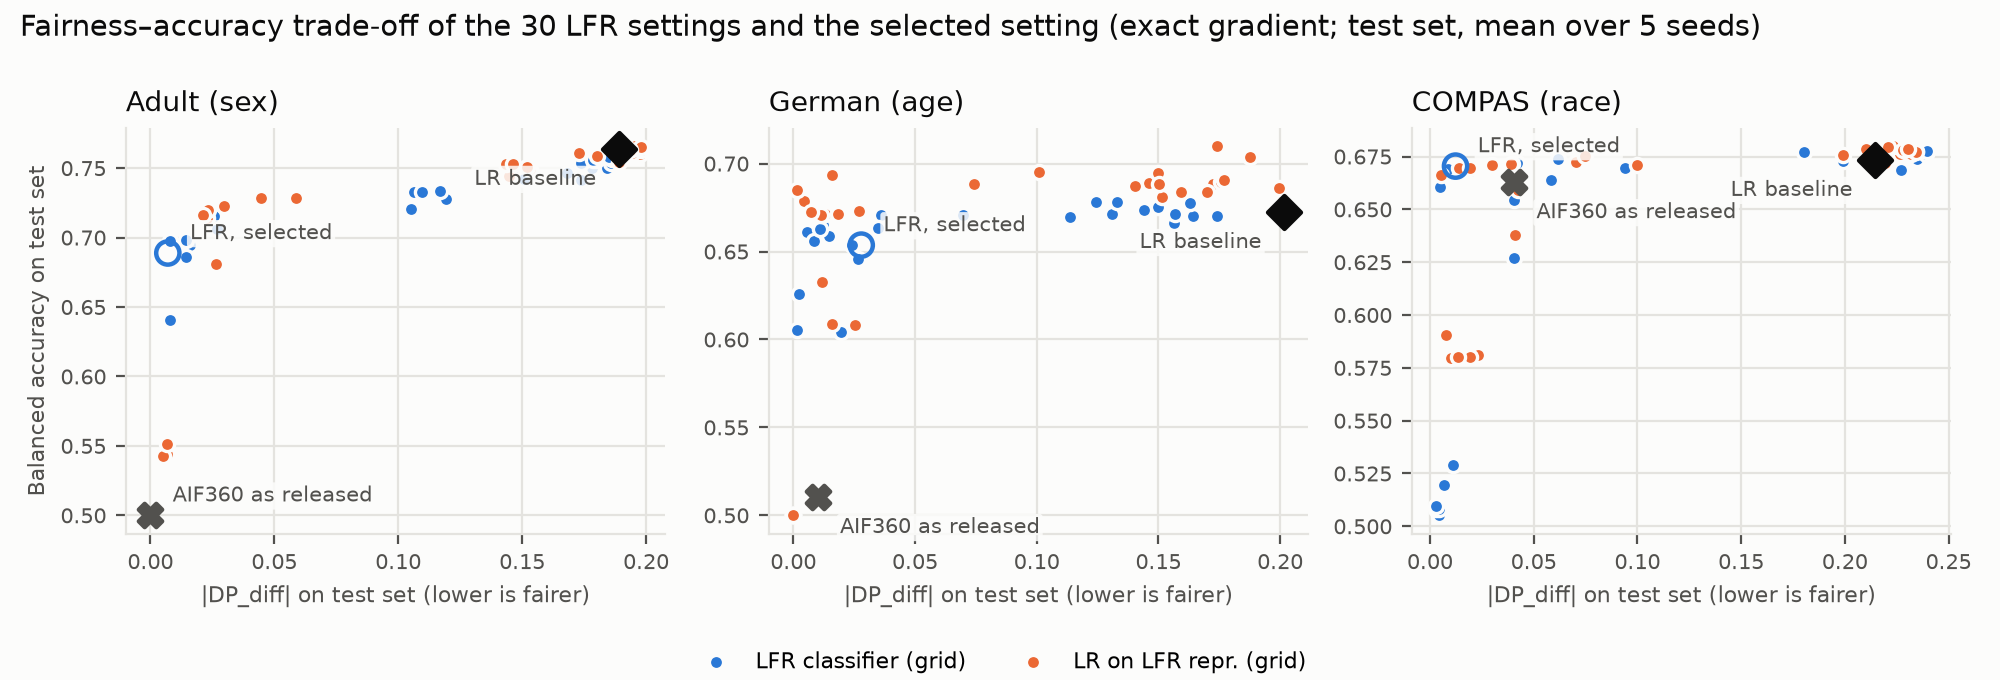

In [11]:
display(Image("results/tradeoff.png"))

### Optimisation and degenerate solutions

Sections 4 and 5 of `results/results.md`.

In [12]:
text = open("results/results.md").read()
start = text.index("## 4. Optimisation")
display(Markdown(text[start:text.index("## Environment")]))

## 4. Optimisation: AIF360 as released vs exact gradient

Same objective, initialisation, bounds and limits (maxiter = maxfun = 5000). 'Iterations' = L-BFGS-B iterations; 'evaluations' = objective evaluations counted by SciPy (with AIF360's finite differences, one per parameter for every gradient). Objective = final value of AIF360's objective on the fit data.

| dataset | fits | n | iterations, median (range) | evaluations, median | converged | objective, mean | seconds per fit, median |
|---|---|---|---|---|---|---|---|
| Adult (sex) | exact gradient, all 30 grid settings | 150 | 241 (26–4993) | 328 | 99% | 1.1554 | 11.1 |
| Adult (sex) | exact gradient, selected setting | 5 | 232 (83–285) | 373 | 100% | 0.3397 | 14.3 |
| Adult (sex) | AIF360 as released, same selected setting | 5 | 4 (4–4) | 5155 | 0% | 0.4889 | 77.7 |
| Adult (sex) | AIF360 as released, AIF360 default (k=5, Az=50) | 5 | 5 (4–6) | 5160 | 0% | 0.7114 | 62.9 |
| German (age) | exact gradient, all 30 grid settings | 150 | 419 (39–1864) | 527 | 100% | 1.1275 | 0.4 |
| German (age) | exact gradient, selected setting | 5 | 601 (192–661) | 664 | 100% | 0.8325 | 0.4 |
| German (age) | AIF360 as released, same selected setting | 5 | 8 (6–8) | 5589 | 0% | 1.4273 | 2.3 |
| German (age) | AIF360 as released, AIF360 default (k=5, Az=50) | 5 | 8 (8–12) | 5287 | 0% | 0.6648 | 1.7 |
| COMPAS (race) | exact gradient, all 30 grid settings | 150 | 369 (36–2483) | 438 | 100% | 2.0004 | 0.6 |
| COMPAS (race) | exact gradient, selected setting | 5 | 250 (175–604) | 352 | 100% | 2.0220 | 0.5 |
| COMPAS (race) | AIF360 as released, same selected setting | 5 | 30 (26–32) | 5076 | 0% | 2.0628 | 3.8 |
| COMPAS (race) | AIF360 as released, AIF360 default (k=5, Az=50) | 5 | 28 (23–39) | 5112 | 0% | 0.7250 | 2.9 |

Stop reasons reported by SciPy (all LFR fits):

- aif360: `STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT` × 30
- exact: `CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL` × 63
- exact: `CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH` × 385
- exact: `STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT` × 2

## 5. Degenerate solutions in the grid (exact gradient, test set)

A fit is counted as degenerate when the pipeline predicts a single class for every test row (DP_diff = 0 and balanced accuracy = 0.5 by construction).

| dataset | pipeline | degenerate fits | by Az (over Ay and seeds) |
|---|---|---|---|
| Adult (sex) | LFR classifier | 11% of 150 | Az=0: 0%, Az=0.1: 0%, Az=0.5: 0%, Az=1: 4%, Az=5: 20%, Az=10: 40% |
| Adult (sex) | LR on LFR repr. | 0% of 150 | Az=0: 0%, Az=0.1: 0%, Az=0.5: 0%, Az=1: 0%, Az=5: 0%, Az=10: 0% |
| German (age) | LFR classifier | 13% of 150 | Az=0: 0%, Az=0.1: 0%, Az=0.5: 0%, Az=1: 4%, Az=5: 28%, Az=10: 48% |
| German (age) | LR on LFR repr. | 13% of 150 | Az=0: 0%, Az=0.1: 0%, Az=0.5: 0%, Az=1: 4%, Az=5: 28%, Az=10: 48% |
| COMPAS (race) | LFR classifier | 11% of 150 | Az=0: 0%, Az=0.1: 0%, Az=0.5: 0%, Az=1: 8%, Az=5: 24%, Az=10: 32% |
| COMPAS (race) | LR on LFR repr. | 0% of 150 | Az=0: 0%, Az=0.1: 0%, Az=0.5: 0%, Az=1: 0%, Az=5: 0%, Az=10: 0% |

